In [4]:
# !pip install pandas
import pandas as pd
import re
import pickle
from datetime import datetime
from bertopic import BERTopic
import matplotlib.pyplot as p
import networkx as nx
import requests
import numpy as np
# import networks_layouts
from matplotlib import colors
import pickle

import ast
def convert_str_to_list(x):
    try:
        return ast.literal_eval(x, '|')
    except:
        return None
def read_pickle(file_name):
    '''Function to read pickles faster'''
    pickle_in = open(file_name, 'rb')
    variable = pickle.load(pickle_in)
    return variable

def write_pickle(variable, file_name):
    '''Function to write pickles faster'''
    pickle_out = open(file_name, 'wb')
    pickle.dump(variable, pickle_out)

#Move all files of one folder to another one:
from os import listdir
from os.path import isfile, join
import os
import shutil

#Read all the files with multiple languages:
folder = 'Multi-lingual-data/'
onlyfiles = [f for f in listdir(folder) if '.csv' in f]
len(onlyfiles)

/Users/anajaramillo/Dropbox/Post-docs/1. Post-doc Mammoth/18. Peace research/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 15:45:02.223000 18301 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


64

In [6]:
#Concatenate all the files together
Complete_DF = []
for file in onlyfiles:
    DF_OA = pd.read_csv(folder+file,header=0, sep=',',
                 lineterminator='\n')
    Complete_DF += [DF_OA]

In [7]:
#Filter out for those results that are duplicated because of common co-authorships:
DataFrame = pd.concat(Complete_DF).drop_duplicates().reset_index()
del DataFrame['index']

In [ ]:
DataFrame.shape
#Out put should be:

(95646, 29)

In [ ]:
pd.DataFrame({'Topic':list(dict(DataFrame['primary_topic.display_name'].value_counts()).keys())}).to_csv('Topics_to_check.csv')

In [9]:
DataFrame = DataFrame[DataFrame['type\r'].isin(['article\r'])]
DataFrame = DataFrame[~DataFrame.doi.isna()]
DataFrame = DataFrame[~DataFrame.display_name.isin([i for i in DataFrame.display_name if 'BOOK' in str(i).upper() or 'CONFERENCE' in str(i).upper()])]
DataFrame = DataFrame.drop_duplicates(['id','authorships.author.id'])
# DataFrame = DataFrame[~DataFrame['topics.domain.display_name'].isna()]
# DataFrame = DataFrame.loc[[i for i in DataFrame.index if 'Social Sciences' in DataFrame['topics.domain.display_name'][i]]]
DataFrame = DataFrame.reset_index()
del DataFrame['index']

def convert_str_to_list(x, data_type=list):
    try:
        if  data_type==list:
            return x.replace('https://openalex.org/', '').split('|')
        elif  data_type==str:
            return x.replace('https://openalex.org/', '')
    except:
        return []

DataFrame['id'] = DataFrame['id'].apply(lambda x: convert_str_to_list(x, str))
# DataFrame['referenced_works'] = DataFrame['referenced_works'].apply(lambda x: convert_str_to_list(x, list))


In [10]:
#Colors used for the plots:
Code_colors_SDGS = read_pickle('Code_colors_SDGS.pkl')

In [11]:
DataFrame = DataFrame[~DataFrame['primary_location.source.display_name'].isna()]

Journals_names = dict(DataFrame['primary_location.source.display_name'].value_counts())

#Information that should be filtered out as they are not journals:
Universities = [k for k in Journals_names.keys() if ('UNIVERSI' in k.upper()) and not('JOURNAL' in k.upper())]
DataFrame = DataFrame[~DataFrame['primary_location.source.display_name'].isin(['Zenodo (CERN European Organization for Nuclear Research)',
                                                      'SSRN Electronic Journal','DOAJ (DOAJ: Directory of Open Access Journals)',
                                                      'Publications (Konstfack University of Arts, Crafts, and Design)',
                                                      'Palgrave Macmillan UK eBooks', 'Cambridge University Press eBooks',
                                                      'Emerald reach proceedings series','Oxford University Press eBooks',
                                                      'Edward Elgar Publishing eBooks','Peace psychology book series',
                                                      'The World Bank eBooks', 'Manchester University Press eBooks',
                                                      'Palgrave Macmillan US eBooks', 'World Bank, Washington, DC eBooks',
                                                      'PubMed', 'Sciendo eBooks', 'Bustan The Middle East Book Review',
                                                      'IGI Global eBooks', 'Policy Press eBooks','Lynne Rienner Publishers eBooks', 
                                                      'Rowman & Littlefield Publishers eBooks', 'Open Collections', 
                                                      'Praeger eBooks', 'World Bank eBooks', 'arXiv (Cornell University)',
                                                      'Preprints.org', 'Lexington Books', 'Intersentia eBooks','Bristol University Press eBooks',
                                                      'Bloomsbury Publishing Plc eBooks', 'LAP LAMBERT Academic Publishing eBooks',
                                                      'University of Texas Press eBooks', 'Nomos Verlagsgesellschaft mbH & Co. KG eBooks',
                                                      'University of Michigan Press eBooks', 'Edinburgh University Press eBooks',
                                                      'Advances in public policy and administration (APPA) book series','transcript Verlag eBooks',
                                                      'I.B.Tauris eBooks', 'Nottingham ePrints (University of Nottingham)', 'Princeton University Press eBooks',
                                                      'SHS Web of Conferences', 'Liverpool University Press eBooks','Greenwood Publishing Group Inc. eBooks',
                                                      'SAGE Open','EMBO Reports', 'Adelphi series', 'Cornell University Press eBooks',
                                                      'Advances in media, entertainment and the arts (AMEA) book series',
                                                      'Bustan The Middle East Book Review','Books','CECS - Publicações / eBooks',
                                                      'German Yearbook of Contemporary History', 'Yearbook of European Law',
                                                        'German Yearbook of International Law','Bookbird/Book bird',
                                                         'UNP - Nebraska eBooks','Northern Lights Film and Media Studies Yearbook',
                                                         'Civil War Book Review','Princeton University Press eBooks',
                                                        'American book review/\x98The \x9cAmerican book review',
                                                        'Polish Political Science Yearbook','PolitBook',
                                                        'Yearbook of Kutaisi Ilia Chavchavadze Public Library',
                                                         'World Bank, Washington, DC eBooks','Choice Reviews Online',
                                                        'SHILAP Revista de lepidopterología', 'Figshare', 'University of the Aegean'
                                                      ]+ Universities
                                                      )]

In [12]:
DataFrame = DataFrame.reset_index()
del DataFrame['index']

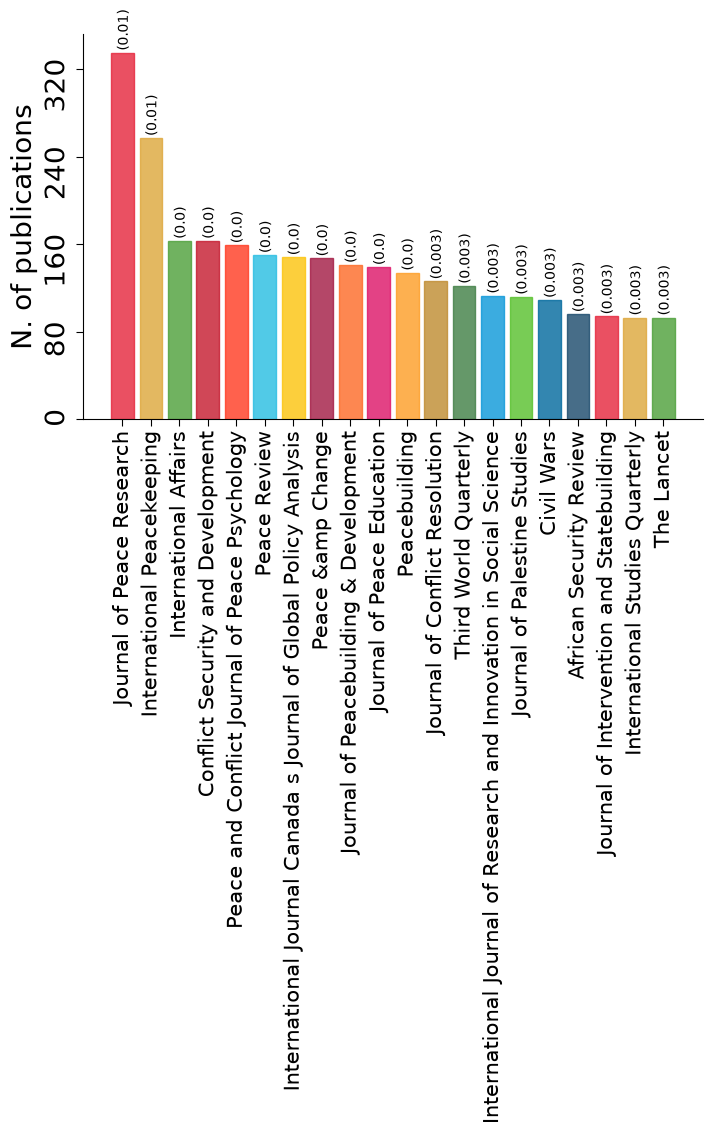

In [13]:
Journals_names = dict(DataFrame['primary_location.source.display_name'].value_counts()[:20])

import matplotlib.pyplot as plt


labels = list(Journals_names.keys())
values = list(Journals_names.values())
sizes = list(Journals_names.values())

plt.rcParams['mathtext.fontset'] = 'dejavusans'
width = 0.6
font_size_out = 12
nrows = 1
ncols = 1
fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(8*ncols,5*nrows), sharex= False, sharey= False,
                       gridspec_kw={'width_ratios': [1]*ncols})

Total_value = DataFrame.shape[0]

for col_plt in range(ncols):


    bars = ax.bar(x = labels, height=sizes, edgecolor='grey',alpha=0.8)

    #Change the color of each bar:
    for i,label in enumerate(labels):
        bars[i].set_color(Code_colors_SDGS[i+1])

        if i < 11:
            ax.text(i-0.2, values[i]+5, '('+ str(np.round(values[i]/Total_value,2)) +')',rotation='vertical', size=10)
        else:
            ax.text(i-0.2, values[i]+5, '('+ str(np.round(values[i]/Total_value,3)) +')',rotation='vertical', size=10)

    # ax.set_title(journal_type, size=20)
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    ax.set_xticklabels(labels, rotation='vertical')
    ax.set_yticklabels(ax.get_yticklabels(), rotation='vertical')

    for spine in ['right', 'top']:
        ax.spines[spine].set_visible(False)

    ax.tick_params('x', size=5, colors="black", labelsize=15)
    ax.tick_params('y', size=5, colors="black", labelsize=20)

    ax.set_xlabel(' ',  size=0)
    ax.set_ylabel('N. of publications',  size=20)

plt.subplots_adjust(wspace=0.2, hspace=0.1)
#     plt.savefig("Hist_fields".pdf", bbox_inches='tight')
plt.show()

In [14]:
%%time
#Set journal information:
Journal_information = {DataFrame['primary_location.source.id'][i].replace('https://openalex.org/',''): DataFrame['primary_location.source.display_name'][i] for i in DataFrame.index}

CPU times: user 775 ms, sys: 5.46 ms, total: 781 ms
Wall time: 797 ms


In [ ]:
import requests
#Bring all the journal information from open alex:
def bring_journal_information(url):
    r = requests.get(url)
    journal_information = r.json()
    return journal_information

# Dict_journal_information = {}
Broken_ids = []
for i,journal_id in  enumerate(list(Journal_information.keys())):
    print(i)
    journal_url_api = 'https://api.openalex.org/'+journal_id
    try:
        Dict_journal_information[journal_id] = bring_journal_information(journal_url_api)
    except:
        Broken_ids += [journal_id]
        pass

In [16]:
len(Journal_information)

11683

In [ ]:
# write_pickle(Dict_journal_information, 'Dict_journal_information_multilingual.pkl')

In [15]:
#Read all the journal information already downloaded:
Dict_journal_information = read_pickle('Dict_journal_information_multilingual.pkl')

In [ ]:
#Count number of journals per contry:
Dict_journals_per_country = {}
Dict_journals_per_country_count = {}
for i in Dict_journal_information.keys():
    try:
        Dict_journals_per_country_count[Dict_journal_information[i]['country_code']] += 1
        Dict_journals_per_country[Dict_journal_information[i]['country_code']] += [i]
    except:
        Dict_journals_per_country_count[Dict_journal_information[i]['country_code']] = 1
        Dict_journals_per_country[Dict_journal_information[i]['country_code']] = [i]
        
        pass

In [17]:
#downloaded from here: https://ourworldindata.org/grapher/world-regions-un2?overlay=download-data (the regions of the world)
World_regions = pd.read_csv('world-regions-un2.csv')
World_regions_M49 = pd.read_csv('RegionM49.csv')
Dict_region_per_country = {World_regions_M49['codeforiati:iso-alpha-2-code'][i]:World_regions_M49['codeforiati:sub-region-name'][i] for i in World_regions_M49.index}
Dict_region_per_country['NA'] = 'Sub-Saharan Africa'
Dict_region_per_country['AN'] = 'Latin America and the Caribbean'
Dict_region_per_country['TW'] = 'Eastern Asia'
Country_codes = pd.read_csv('Country_codes.csv', delimiter=',')
Country_GDP = pd.read_csv('API_NY.GDP.PCAP.CD_DS2_en_csv_v2_4770417.csv')

In [ ]:
#Bring the country that belong to each region:
Dict_countries_regions = {}
for k in Dict_journals_per_country_count.keys():
    try:
        Dict_countries_regions[World_regions_M49[World_regions_M49['codeforiati:iso-alpha-2-code'] == k]['codeforiati:sub-region-name'].iloc[0]] += [k] 
    except:
        try:
            Dict_countries_regions[World_regions_M49[World_regions_M49['codeforiati:iso-alpha-2-code'] == k]['codeforiati:sub-region-name'].iloc[0]] = [k] 
        except:
            pass
        pass


In [20]:
#Get the number of journals per country and per region:
Number_journals_per_region = {}

for k,countries in Dict_countries_regions.items():
    for v in countries:
        try:
            Number_journals_per_region[k] += Dict_journals_per_country[v]
        except:
            Number_journals_per_region[k] = Dict_journals_per_country[v]
            pass

In [21]:
#To clean the dataset from the openalex link:
DataFrame['primary_location.source.id'] = [i.replace('https://openalex.org/','') for i in DataFrame['primary_location.source.id']]

In [22]:
%%time
#Get the average citations of each journal:
Dict_journal_avg_citations = {}
for country,journals in Dict_journals_per_country.items():
    for journal_id in journals:
        try:
            Filtered_DF = DataFrame[DataFrame['primary_location.source.id'] ==journal_id]
            Dict_journal_avg_citations[journal_id] = sum(Filtered_DF['cited_by_count'])
        except:
            pass

CPU times: user 28 s, sys: 301 ms, total: 28.3 s
Wall time: 28.8 s


In [23]:
#Get the average citation of the journal for each region:
Dict_journal_region_avg_citations = {}

for region in Dict_countries_regions.keys():
    Dict_journal_region_avg_citations[region] = {}
    
    for country in Dict_countries_regions[region]:
        for journal_id in Dict_journals_per_country[country]:
            Dict_journal_region_avg_citations[region][journal_id] = Dict_journal_avg_citations[journal_id]
    
    Dict_journal_region_avg_citations[region] = {k: v for k, v in sorted(Dict_journal_region_avg_citations[region].items(), key=lambda item: item[1], reverse = True)}
            

In [ ]:
import matplotlib.pyplot as plt

#Create a function to plot te journals information:
def plot_journals(labels,values,sizes,color):
    
    plt.rcParams['mathtext.fontset'] = 'dejavusans'
    width = 0.6
    font_size_out = 7
    nrows = 1
    ncols = 1
    fig, ax = plt.subplots(ncols=ncols, nrows=nrows,figsize=(4*ncols,2*nrows), sharex= False, sharey= False,
                           gridspec_kw={'width_ratios': [1]*ncols})
    
    # Total_value = DataFrame.shape[0]
    
    for col_plt in range(ncols):
    
    
        bars = ax.bar(x = labels, height=sizes, edgecolor='white',alpha=0.8, color = color)
    
        # #Change the color of each bar:
        # for i,label in enumerate(labels):
        #     bars[i].set_color(Code_colors_SDGS[i+1])
    
            # if i < 11:
            #     ax.text(i-0.2, values[i]+5, '('+ str(np.round(values[i]/Total_value,2)) +')',rotation='vertical', size=font_size_out)
            # else:
            #     ax.text(i-0.2, values[i]+5, '('+ str(np.round(values[i]/Total_value,3)) +')',rotation='vertical', size=font_size_out)
    
        # ax.set_title(journal_type, size=20)
        ax.yaxis.set_major_locator(plt.MaxNLocator(5))
        ax.set_xticklabels(labels, rotation='vertical')
        ax.set_yticklabels(ax.get_yticklabels(), rotation='vertical')
    
        for spine in ['right', 'top']:
            ax.spines[spine].set_visible(False)
    
        ax.tick_params('x', size=5, colors="black", labelsize=font_size_out+2)
        ax.tick_params('y', size=5, colors="black", labelsize=font_size_out-1)
    
        ax.set_xlabel(' ',  size=0)
        ax.set_ylabel('N. of citations',  size=font_size_out+3)
    #     for i in range(4):
    #         ax.axhline(y=40000*i, color='darkgrey', ls='--')
        # ax.set_yscale('log')
    
        # ax.set_title(Demographic_variables[col_plt],  size=30)
    
    
    plt.subplots_adjust(wspace=0.2, hspace=0.1)
    #     plt.savefig("Hist_fields".pdf", bbox_inches='tight')
    plt.show()

In [25]:
#Get the number of papers for each journal:
Dict_journal_number_of_papers = dict(DataFrame['primary_location.source.id'].value_counts())

Dict_journal_region_number_of_papers = {}

for region in Dict_countries_regions.keys():
    Dict_journal_region_number_of_papers[region] = {}
    
    for country in Dict_countries_regions[region]:
        for journal_id in Dict_journals_per_country[country]:
            Dict_journal_region_number_of_papers[region][journal_id] = Dict_journal_number_of_papers[journal_id]
    
    Dict_journal_region_number_of_papers[region] = {k: v for k, v in sorted(Dict_journal_region_number_of_papers[region].items(), key=lambda item: item[1], reverse = True)}
            

Eastern Europe


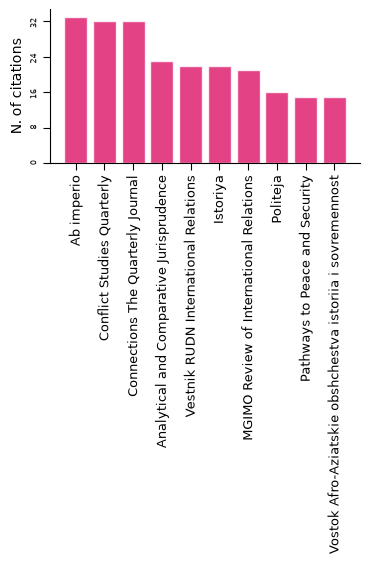

Southern Asia


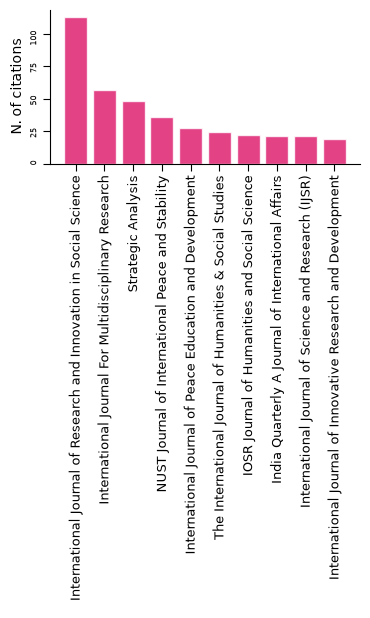

Northern Africa


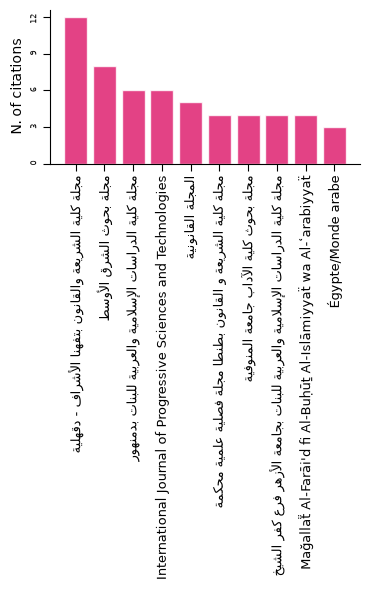

Western Asia


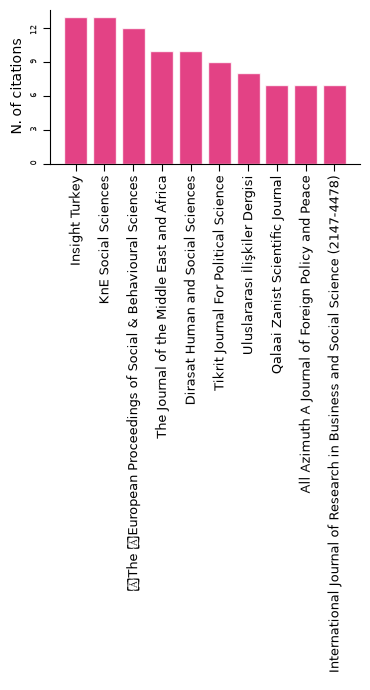

Latin America and the Caribbean


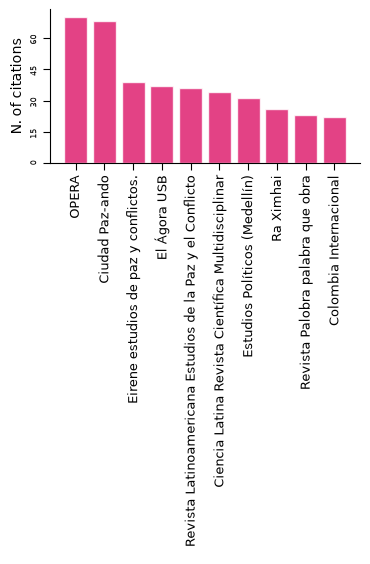

Southern Europe


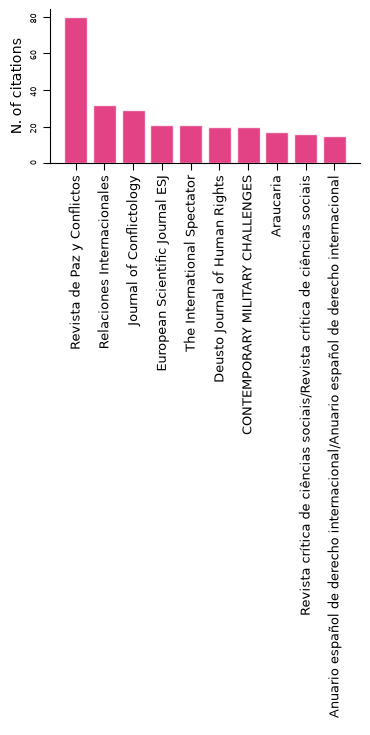

Northern Europe


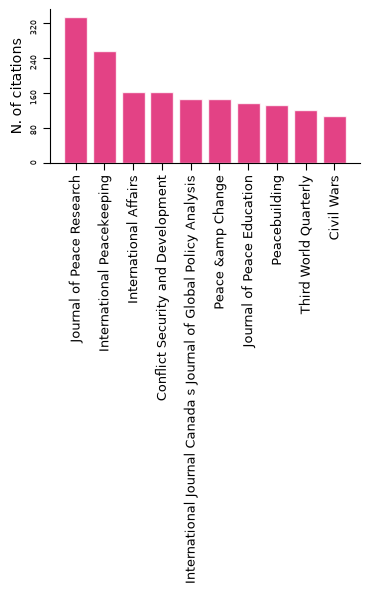

Western Europe


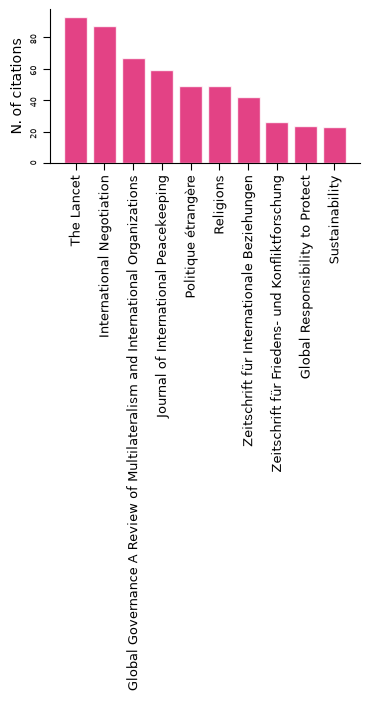

Northern America


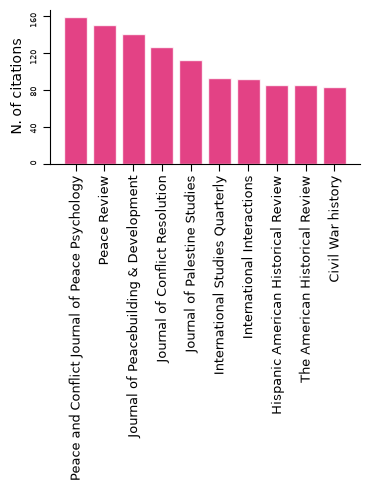

South-eastern Asia


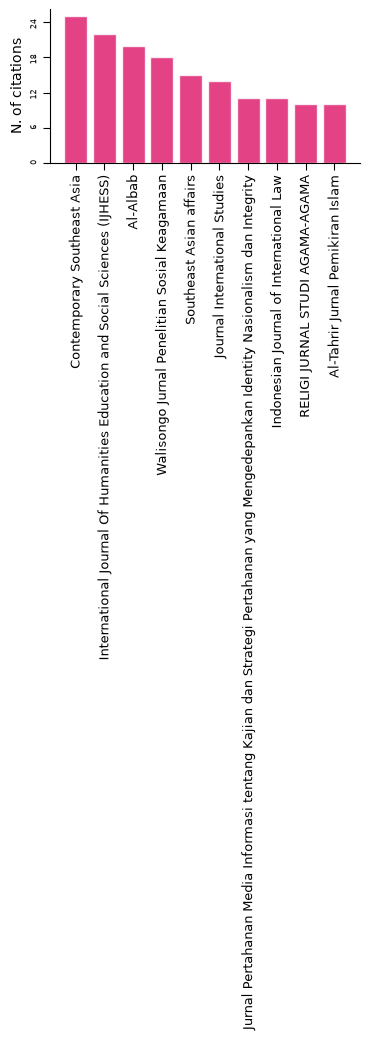

Polynesia


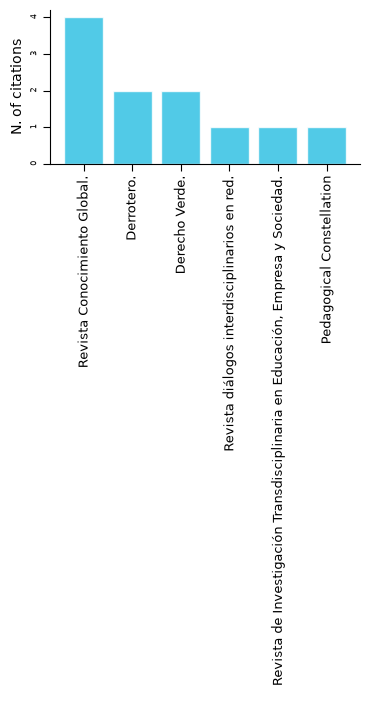

Eastern Asia


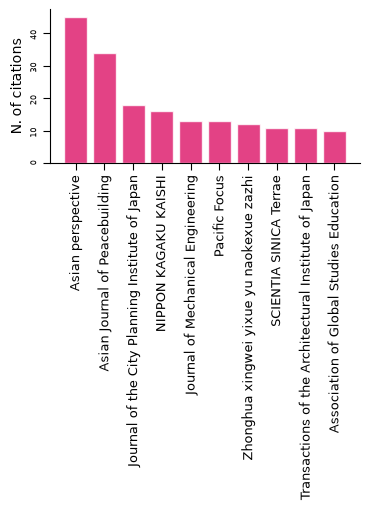

Australia and New Zealand


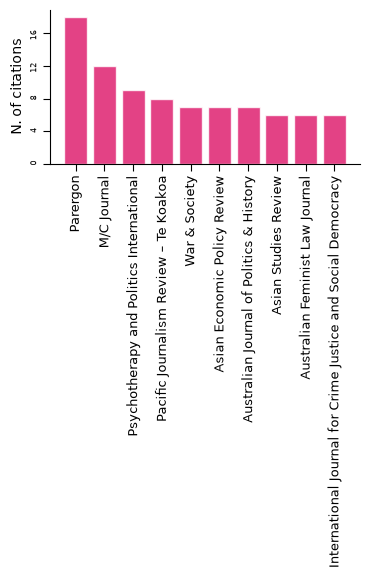

Sub-Saharan Africa


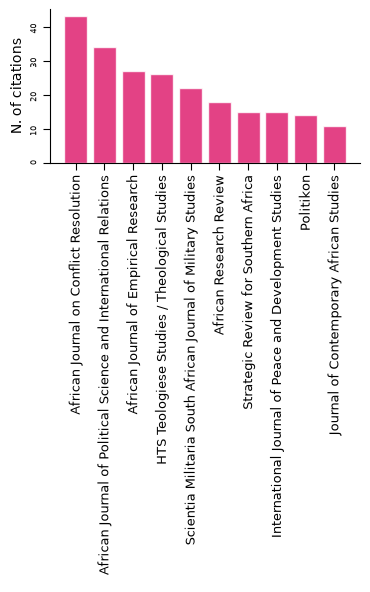

Micronesia


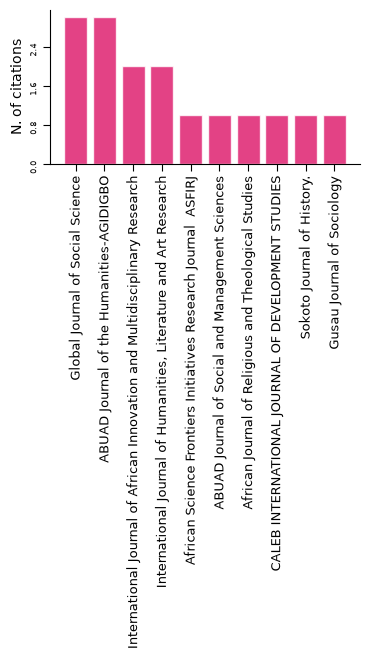

Central Asia


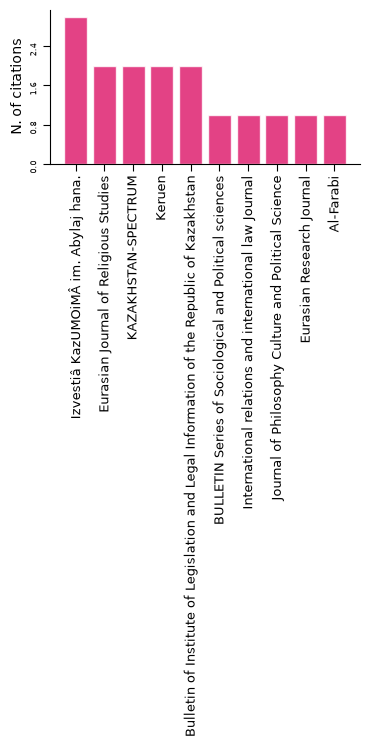

In [26]:
#Get the number of papers per journal for the regions:
PD_Regions_journals = {'Region': [], 'Journal':[], 'Number of papers':[]}
for i,region in enumerate(Dict_journal_region_number_of_papers):
    print(region)
    journal_ids = [journal_id for journal_id in list(Dict_journal_region_number_of_papers[region].keys())[:10]]
    labels = [Journal_information[journal_id] for journal_id in journal_ids]
    values = [Dict_journal_region_number_of_papers[region][l] for l in journal_ids]
    sizes = [Dict_journal_region_number_of_papers[region][l] for l in journal_ids]

    for i in range(len(labels)):
        PD_Regions_journals['Region']+=[region]
        PD_Regions_journals['Journal']+=[labels[i]]
        PD_Regions_journals['Number of papers']+=[sizes[i]]

    plot_journals(labels,values,sizes,Code_colors_SDGS[i+1])


Eastern Europe


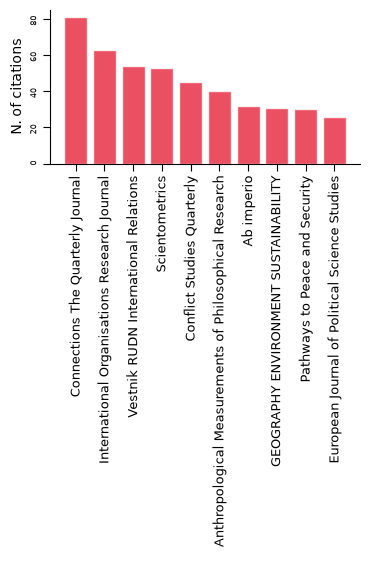

Southern Asia


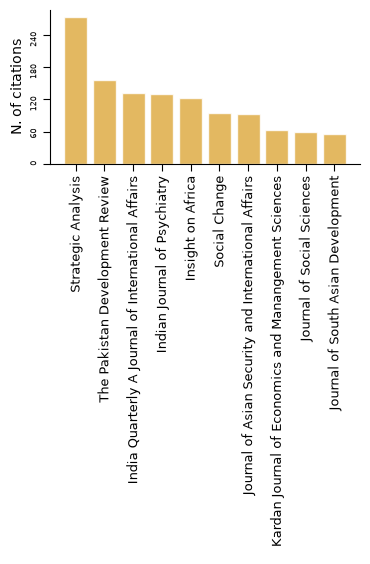

Northern Africa


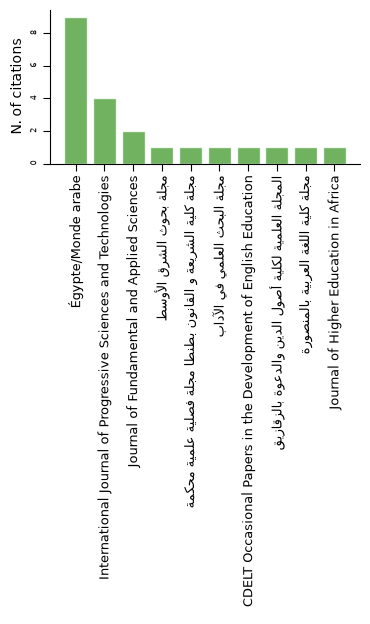

Western Asia


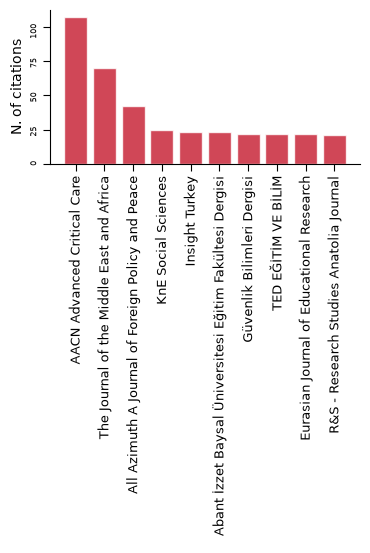

Latin America and the Caribbean


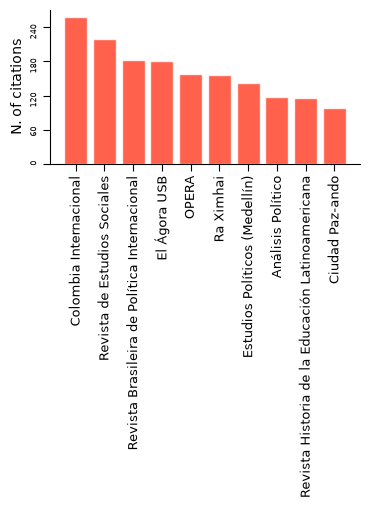

Southern Europe


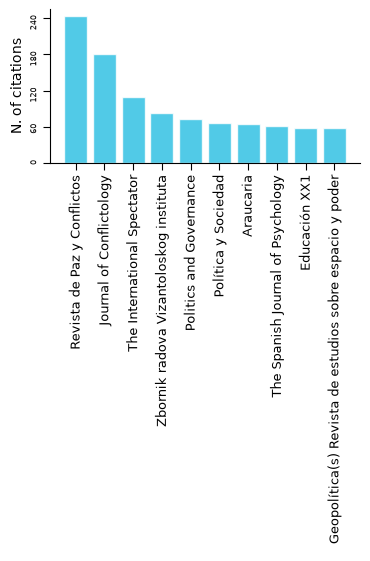

Northern Europe


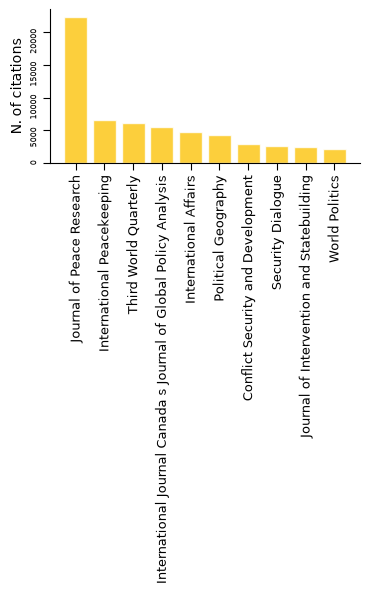

Western Europe


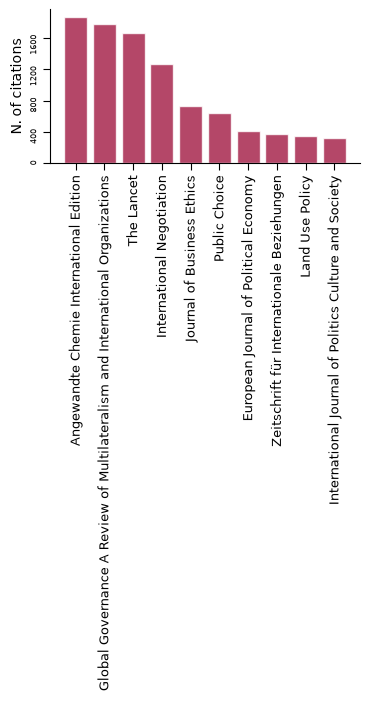

Northern America


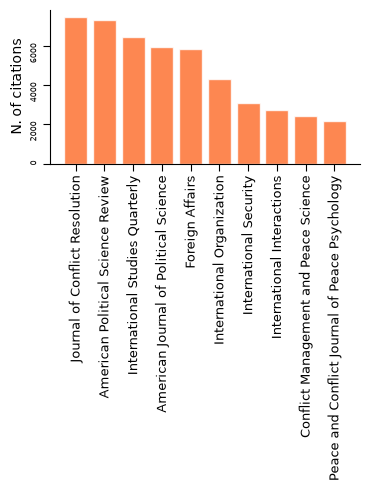

South-eastern Asia


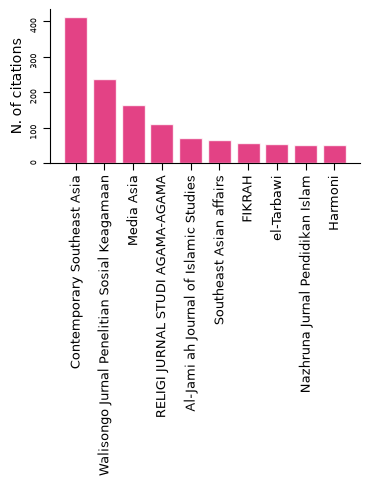

Polynesia


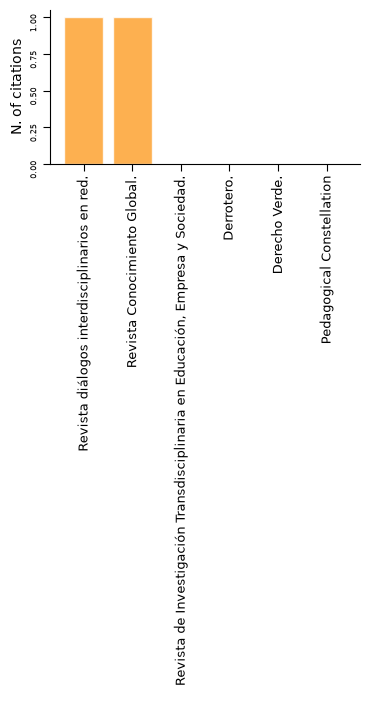

Eastern Asia


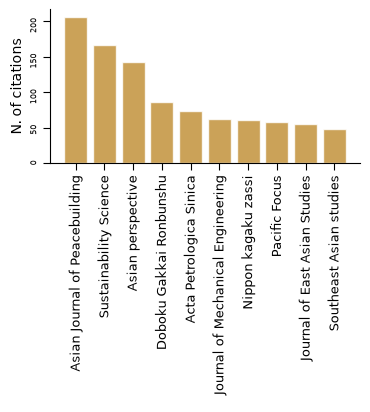

Australia and New Zealand


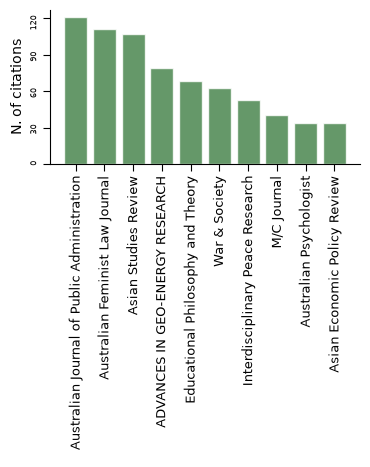

Sub-Saharan Africa


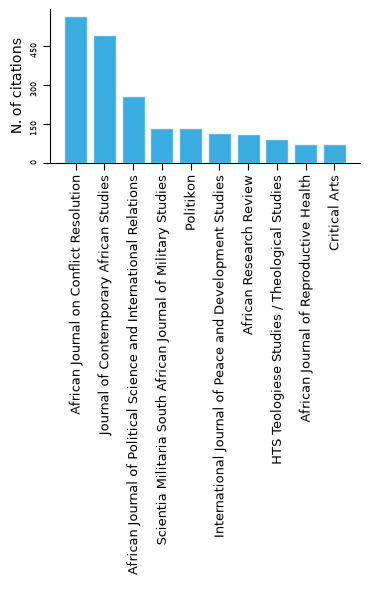

Micronesia


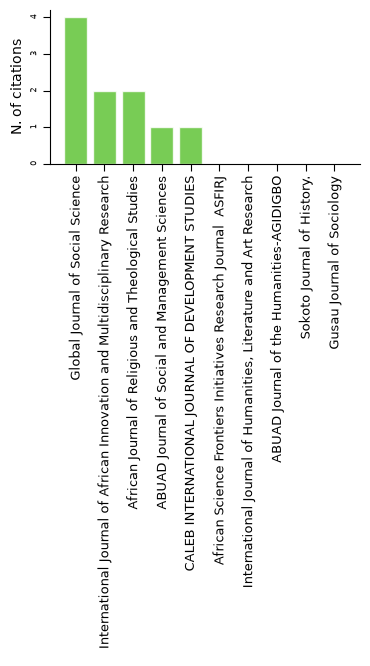

Central Asia


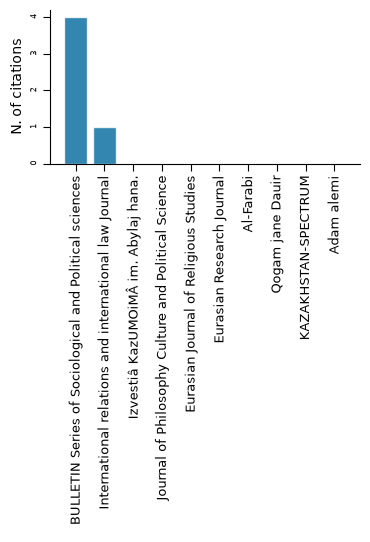

In [29]:
#Make plots for the top 10 journals per reagion with the number of citations and from here select with are the journals to check:
Filtered_journals = {}
for i,region in enumerate(Dict_journal_region_number_of_papers):
    print(region)
    journal_ids = [journal_id for journal_id in list(Dict_journal_region_avg_citations[region].keys())[:10]]
    labels = [Journal_information[journal_id] for journal_id in journal_ids]
    values = [Dict_journal_region_avg_citations[region][l] for l in journal_ids]
    sizes = [Dict_journal_region_avg_citations[region][l] for l in journal_ids]       
    
    plot_journals(labels,values,sizes,Code_colors_SDGS[i+1])
    Filtered_journals[region] = [l for l in journal_ids if Dict_journal_region_avg_citations[region][l] > 0] 

In [30]:
#Get the abstracts of the filtered journals per region:
List_abstracts = {}
for region in Filtered_journals:
    Filtered_DF = DataFrame[DataFrame['primary_location.source.id'].isin(Filtered_journals[region])]
    List_abstracts[region] = {Filtered_DF['id'][i]:Filtered_DF['abstract'][i] for i in Filtered_DF.index }
    